In [ ]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
import pandas as pd
import tracemalloc
from scipy.sparse.linalg import gmres, LinearOperator

import time as tm
from time import perf_counter
import tracemalloc

np.random.seed(42)

num_patches = 4  # the number of patches


Lambda_b = 1826
mu_b = 0.0083              # all the parameters for birds
d_b = 1.695
beta_b = 6.9
beta_pb = 5.99e-8

Lambda_c = np.array([41667,18333,30000,23000,16000])               # defining lambdas

mu_c = (1/60)* np.ones(num_patches)

beta_c = np.array([4.973799810286691e-11,1.7774715831585466e-9,3e-11,2.8e-11,5e-11 ])[0:num_patches]                 # defining all the transmission rates
beta_bc = np.array([1.2068622431950374e-09, 1.4091530012505374e-09,1.5e-9,1.3e-9,1.1e-9])[0:num_patches]
beta_pc = np.array([7.822681712077197e-15, 6.459020018020026e-15,6e-15,7e-15,7.2e-15])[0:num_patches]

q_c = np.array([2,2,2,2,2])[0:num_patches]
chi_c = 6.083                                              # all the parameter associated with the cattles
phi_c = 30.4167
gamma_c = np.array([2,2,2,2,2])[0:num_patches]
kappa_c = 1.2

rho = 3.04e4
theta = 0.25

def generate_pij(num_patches, t):
    np.random.seed(42+int(t * 1000) % 2**32)
    pij = np.random.uniform(0.05, 1.0, size=(num_patches, num_patches))       # Generating pij the needed mobility
    pij = np.clip(pij, 0.1, 0.9)
    col_sums = np.sum(pij, axis=0)
    pij = pij / col_sums
    return pij

def lambda_c(Sci, Eci, Ici, Tci, Rci, t):
    pij = generate_pij(num_patches, t)  # shape: (num_patches, num_patches)
    lambdas = np.zeros(num_patches)

    for i in range(num_patches):  # loop over target patches (i)
        lambda_i = 0
        for j in range(num_patches):  # loop over source patches (j)
            numerator1 = 0
            numerator2 = 0
            denominator = 0
            for k in range(num_patches):
                pkj = pij[k, j]
                numerator1 += pkj * Eci[k]
                numerator2 += pkj * Ici[k]
                denominator += pkj * (Sci[k] + Eci[k] + Ici[k] + Rci[k] - Tci[k])
            denominator = max(denominator, 1e-6)  # avoid division by zero
            lambda_i += pij[i, j] * beta_c[j] * (numerator1 + kappa_c * numerator2) / denominator
        lambdas[i] = lambda_i

    return lambdas


def system(t, y):
    Sb, Ib, P = y[0], y[1], y[2]
    Sci = y[3:3+num_patches]
    Eci = y[3+num_patches:3+2*num_patches]
    Ici = y[3+2*num_patches:3+3*num_patches]
    Tci = y[3+3*num_patches:3+4*num_patches]
    Rci = y[3+4*num_patches:3+5*num_patches]

    lambdaci = lambda_c(Sci, Eci, Ici, Tci, Rci, t)

    N_b = Sb + Ib
    total_infectious_cattle = np.sum(Ici + Eci)
    total_cattle = np.sum(Sci + Eci + Ici + Tci + Rci)

    dSb_dt = Lambda_b - (beta_b * Ib / max(N_b, 1e-6) + beta_pb * P) * Sb - mu_b * Sb
    dIb_dt = (beta_b * Ib / max(N_b, 1e-6) + beta_pb * P) * Sb - (mu_b + d_b) * Ib
    dP_dt = rho * (Ib + total_infectious_cattle) - theta * P

    dSci_dt = np.zeros(num_patches)
    dEci_dt = np.zeros(num_patches)
    dIci_dt = np.zeros(num_patches)
    dTci_dt = np.zeros(num_patches)
    dRci_dt = np.zeros(num_patches)

    for i in range(num_patches):
        infection_rate = lambdaci[i] + beta_bc[i] * Ib / max(N_b, 1e-6) + beta_pc[i] * P
        dSci_dt[i] = Lambda_c[i] - infection_rate * Sci[i] - mu_c[i] * Sci[i]
        dEci_dt[i] = infection_rate * Sci[i] - (mu_c[i] + q_c[i] + chi_c) * Eci[i]          # Taking each of the cattle in a for loop to get the trajctories
        dIci_dt[i] = q_c[i] * Eci[i] - (mu_c[i] + phi_c) * Ici[i]
        dTci_dt[i] = chi_c * Eci[i] + phi_c * Ici[i] - (mu_c[i] + gamma_c[i]) * Tci[i]
        dRci_dt[i] = gamma_c[i] * Tci[i] - mu_c[i] * Rci[i]

    return np.concatenate(([dSb_dt, dIb_dt, dP_dt],
                           dSci_dt, dEci_dt, dIci_dt, dTci_dt, dRci_dt))     # solving the compartmental models numerically and get the solution


Sb0 = 100000
Ib0 = 1000
P0 = 1000
Sci0 = np.array([2500000,1100000,1000000,1200000,2000000,900000])[0:num_patches]    # Setting all of the inital conditions
Eci0 = np.array([10,5,6,9,11])[0:num_patches]
Ici0 = np.array([1,1,1,1,1])[0:num_patches]
Tci0 = np.array([1,1,1,1,1])[0:num_patches]
Rci0 = np.array([0,0,0,0,0])[0:num_patches]

y0 = np.concatenate(([Sb0, Ib0, P0], Sci0, Eci0, Ici0, Tci0, Rci0))


t_span = (0,24)
t_eval = np.linspace(*t_span,720)                                          # solving the system for the given time stam
sol = solve_ivp(system, t_span, y0, t_eval=t_eval, method='RK45')


P_list = sol.y[2]
Ici_list = sol.y[3+2*num_patches:3+3*num_patches]
pij_list = []

for time in sol.t:
    pij = generate_pij(num_patches, time)
    pij_list.append(pij.flatten())


columns_pij = [f"p{i+1}{j+1}" for i in range(num_patches) for j in range(num_patches)]
columns_Ici = [f"Ici_patch_{i+1}" for i in range(num_patches)]

df = pd.DataFrame(pij_list, columns=columns_pij)
df['P'] = P_list
for i in range(num_patches):
    df[columns_Ici[i]] = Ici_list[i]

print(df)             # storing all of the data points in a dataframe

          p11       p12       p13       p14       p21       p22       p23  \
0    0.196433  0.434240  0.635293  0.236532  0.095947  0.095627  0.089644   
1    0.227847  0.049715  0.434172  0.357342  0.268445  0.250224  0.110987   
2    0.109471  0.068317  0.310350  0.112217  0.282575  0.477874  0.454120   
3    0.524700  0.303436  0.234249  0.351804  0.139856  0.089417  0.272415   
4    0.321567  0.183424  0.293867  0.307945  0.039603  0.545339  0.260528   
..        ...       ...       ...       ...       ...       ...       ...   
715  0.112017  0.122652  0.439580  0.365907  0.277131  0.225496  0.219168   
716  0.256538  0.263797  0.097300  0.470404  0.256538  0.165090  0.204305   
717  0.170246  0.053425  0.381777  0.196372  0.404125  0.443369  0.400088   
718  0.211252  0.249838  0.198640  0.192568  0.186872  0.290341  0.087570   
719  0.560877  0.179079  0.114135  0.169275  0.136623  0.123347  0.206816   

          p24       p31       p32  ...       p34       p41       p42  \
0  

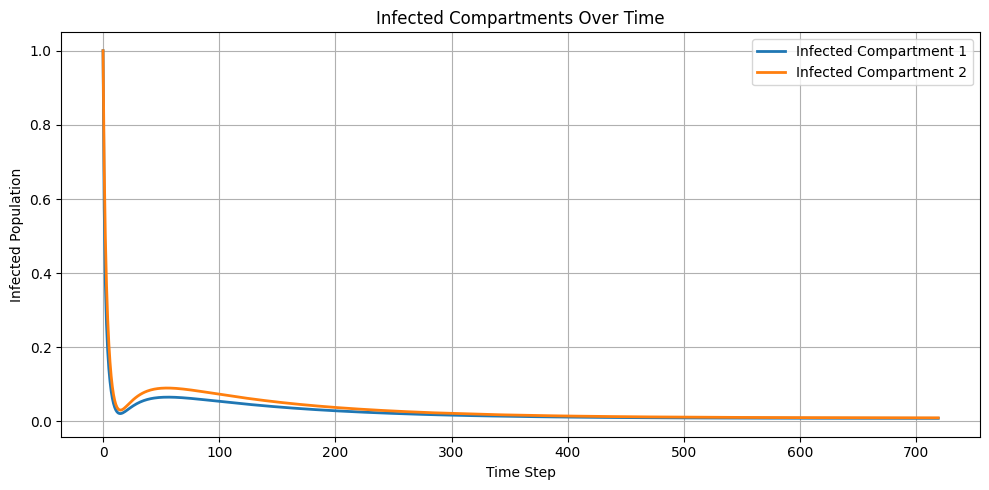

In [ ]:
import matplotlib.pyplot as plt

# Extract last two columns
infected_1 = df.iloc[:, -2]
infected_2 = df.iloc[:, -1]

# Create a time axis (e.g., assuming each row is a time step)
time = df.index

# Plot
plt.figure(figsize=(10, 5))
plt.plot(time, infected_1, label='Infected Compartment 1', linewidth=2)
plt.plot(time, infected_2, label='Infected Compartment 2', linewidth=2)
plt.xlabel('Time Step')
plt.ylabel('Infected Population')
plt.title('Infected Compartments Over Time')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler

last_5_scalers = []              # scaling all of the coloumns

for col in df.columns:
    scaler = StandardScaler()
    df[col] = scaler.fit_transform(df[[col]])
    last_5_scalers.append(scaler)

last_5_scalers = last_5_scalers[-num_patches:]

In [ ]:
def get_data(df,lag=20):
    col_names = df.columns
    X = []
    y = []
    n = df.shape[0]
    for j in range(0,n-lag):
        tx = []
        ty = []
        for i in col_names[0:-num_patches]:
            values = df[i].values[j:j+lag+1]
            tx.append(values)
        for i in col_names[-num_patches:]:
            values = df[i].values[j:j+lag]
            tx.append(values)
        tx = np.concatenate(tx)
        X.append(tx)
        for i in col_names[-num_patches:]:
            ty.append(df[i].values[j+lag])
        y.append(ty)
    return np.array(X),np.array(y)

In [ ]:
lag = 3
X,y = get_data(df,lag)
print(X.shape)
print(y.shape)

(717, 80)
(717, 4)


In [ ]:
n = len(X)

training_ratio = int(0.5*len(X))

X_train,X_test = X[0:training_ratio],X[training_ratio:]
y_train,y_test = y[0:training_ratio],y[training_ratio:]

In [ ]:

class ELM:
    def __init__(self, input_dim, hidden_dim, output_dim, activation='sigmoid'):
        self.input_dim = input_dim
        self.hidden_dim = hidden_dim
        self.output_dim = output_dim
        self.activation = activation
        self.W = np.random.randn(input_dim, hidden_dim)
        self.b = np.random.randn(hidden_dim)

    def _activation(self, x):
        if self.activation == 'sigmoid':
            x = np.clip(x, -500, 500)
            return 1 / (1 + np.exp(-x))
        elif self.activation == 'tanh':
            return np.tanh(x)
        elif self.activation == 'relu':
            return np.maximum(0, x)
        else:
            raise ValueError("Unsupported activation")

    def fit(self, X, y, regularization=1e-3, rtol=1e-5):
        from time import perf_counter

        # Start tracking time and peak memory
        start_time = perf_counter()
        tracemalloc.start()

        # 1. Compute hidden layer activation matrix H (N x L)
        H = self._activation(X @ self.W + self.b)

        # 2. Solve weights using GMRES (Matrix-Free Normal Equations)
        L = self.hidden_dim

        def matvec(v):
            return H.T @ (H @ v) + regularization * v

        A_operator = LinearOperator((L, L), matvec=matvec, dtype=H.dtype)
        b_vector = H.T @ y

        # Track total GMRES iterations across outputs
        total_iterations = 0

        # Handle multi-output targets if y has multiple columns
        if y.ndim > 1 and y.shape[1] > 1:
            beta_list = []
            for i in range(y.shape[1]):
                iters = [0]
                def callback(rk):
                    iters[0] += 1

                beta_col, exit_code = gmres(A_operator, b_vector[:, i], rtol=rtol, callback=callback, callback_type='legacy')
                total_iterations += iters[0]

                if exit_code != 0:
                    print(f"Warning: GMRES for output column {i} exited with code {exit_code}")
                beta_list.append(beta_col)
            self.beta = np.column_stack(beta_list)
        else:
            iters = [0]
            def callback(rk):
                iters[0] += 1

            self.beta, exit_code = gmres(A_operator, b_vector, rtol=rtol, callback=callback, callback_type='legacy')
            total_iterations = iters[0]

            if exit_code != 0:
                print(f"Warning: GMRES exited with code {exit_code}")
            if y.ndim > 1:
                self.beta = self.beta.reshape(-1, 1)

        # Stop tracking
        end_time = perf_counter()
        current, peak_memory = tracemalloc.get_traced_memory()
        tracemalloc.stop()

        # Store training metrics for comparison
        self.training_metrics = {
            "training_time_sec": end_time - start_time,
            "peak_memory_mb": peak_memory / (1024 * 1024),
            "train_residual_norm": float(np.linalg.norm(H @ self.beta - y)),
            "gmres_iterations": total_iterations
        }

    def predict(self, X):
        H = self._activation(X @ self.W + self.b)
        return H @ self.beta

# --- Execution Setup ---
n = int(1.02 * 1e6)           # hidden nodes
m = (lag + 1) * num_patches * num_patches + lag * num_patches + lag + 1

elm = ELM(input_dim=m, hidden_dim=n, output_dim=num_patches, activation='relu')

# Train the model using GMRES optimization
elm.fit(X_train, y_train, regularization=1e-3, rtol=1e-5)

# --- Print the Comparative Metrics ---

In [ ]:
preds = []
for i in range(num_patches):
    preds.append([])

In [ ]:
print("length of test is",len(y_test))
t = []
t.append(X_test[0])
t = np.array(t)
pred = elm.predict(t)
print(pred)

length of test is 359
[[-0.39747598 -0.26402023 -0.23755688 -0.2841423 ]]


In [ ]:
for i in range(len(preds)):
    preds[i].append(pred[0][i])

for i in range(1,len(y_test)):
    print("Iteration number",i)
    t = []
    m = X_test[i]
    for i in range(num_patches):
        index = 10*(num_patches-i-1)+1
        m[-index]=pred[0][i]
    t.append(m)
    t = np.array(t)
    pred = elm.predict(t)
    for i in range(len(preds)):
        preds[i].append(pred[0][i])

Iteration number 1
Iteration number 2
Iteration number 3
Iteration number 4
Iteration number 5
Iteration number 6
Iteration number 7
Iteration number 8
Iteration number 9
Iteration number 10
Iteration number 11
Iteration number 12
Iteration number 13
Iteration number 14
Iteration number 15
Iteration number 16
Iteration number 17
Iteration number 18
Iteration number 19
Iteration number 20
Iteration number 21
Iteration number 22
Iteration number 23
Iteration number 24
Iteration number 25
Iteration number 26
Iteration number 27
Iteration number 28
Iteration number 29
Iteration number 30
Iteration number 31
Iteration number 32
Iteration number 33
Iteration number 34
Iteration number 35
Iteration number 36
Iteration number 37
Iteration number 38
Iteration number 39
Iteration number 40
Iteration number 41
Iteration number 42
Iteration number 43
Iteration number 44
Iteration number 45
Iteration number 46
Iteration number 47
Iteration number 48
Iteration number 49
Iteration number 50
Iteration

In [ ]:
actuals = []
for i in range(num_patches):
    actuals.append([])

for i in y_test:
    for j in range(len(actuals)):
        actuals[j].append(i[j])

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

def plot_predictions(pred, act, scaler, i):
    # Ensure inputs are NumPy arrays
    pred = np.array(pred).reshape(-1, 1)
    act = np.array(act).reshape(-1, 1)

    # Inverse transform to original scale
    y_pred_original = scaler.inverse_transform(pred)
    y_test_original = scaler.inverse_transform(act)

    # Calculate R² and MSE
    r2 = r2_score(y_test_original, y_pred_original)
    mse = mean_squared_error(y_test_original, y_pred_original)

    # Create time axis in months (assuming 30 samples per month)
    months = np.arange(len(y_test_original)) / 30  # One tick per month

    # Plot
    '''
    plt.figure(figsize=(10, 5))
    plt.plot(months, y_test_original, label='Actual', linewidth=2)
    plt.plot(months, y_pred_original, label='Predicted', linewidth=2)
    plt.title(f'Actual vs Predicted of Cattle {i+1}\nR² = {r2:.4f} | MSE = {mse:.4e}', fontsize=14)
    plt.xlabel('Time (in months)')
    plt.ylabel(f'Cattle {i+1} infected compartment')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()
    '''

    return r2, mse

In [ ]:

print("==========================================")
print("     GMRES-OPTIMIZED ELM TRAINING METRICS ")
print("==========================================")
print(f"Training Time          : {elm.training_metrics['training_time_sec']:.4f} seconds")
print(f"Peak Memory Usage      : {elm.training_metrics['peak_memory_mb']:.2f} MB")
print(f"Training Residual Norm : {elm.training_metrics['train_residual_norm']:.4f}")
print(f"GMRES Iterations       : {elm.training_metrics['gmres_iterations']}")
print("==========================================")
for i in range(num_patches):
    print("Length of predictions",len(preds[i]))
    print("Length of actual is",len(actuals[i]))
    a,b = plot_predictions(preds[i], actuals[i],last_5_scalers[i],i)
    print(f"Cattle Population Number {i + 1}")
    print(f"R² Score : {a:.4f}")
    print(f"MSE      : {b:.4e}")
    print("-" * 35)

     GMRES-OPTIMIZED ELM TRAINING METRICS 
Training Time          : 74.6596 seconds
Peak Memory Usage      : 5571.96 MB
Training Residual Norm : 0.0071
GMRES Iterations       : 110
Length of predictions 359
Length of actual is 359
Cattle Population Number 1
R² Score : -0.1727
MSE      : 2.2887e-05
-----------------------------------
Length of predictions 359
Length of actual is 359
Cattle Population Number 2
R² Score : -0.0425
MSE      : 2.6856e-06
-----------------------------------
Length of predictions 359
Length of actual is 359
Cattle Population Number 3
R² Score : -0.3317
MSE      : 2.4085e-06
-----------------------------------
Length of predictions 359
Length of actual is 359
Cattle Population Number 4
R² Score : -0.1770
MSE      : 4.2248e-06
-----------------------------------


In [ ]:
'''
cattle = 2

==========================================
     GMRES-OPTIMIZED ELM TRAINING METRICS
==========================================
Training Time          : 55.4195 seconds
Peak Memory Usage      : 5571.96 MB
Training Residual Norm : 0.0165
GMRES Iterations       : 70
==========================================
Length of predictions 359
Length of actual is 359
Cattle Population Number 1
R² Score : 0.9836
MSE      : 3.2014e-07
-----------------------------------
Length of predictions 359
Length of actual is 359
Cattle Population Number 2
R² Score : 0.9802
MSE      : 5.0852e-08
-----------------------------------


==========================================
     GMRES-OPTIMIZED ELM TRAINING METRICS
==========================================
Training Time          : 84.6317 seconds
Peak Memory Usage      : 5571.96 MB
Training Residual Norm : 0.0139
GMRES Iterations       : 125
==========================================
Length of predictions 359
Length of actual is 359
Cattle Population Number 1
R² Score : 0.5255
MSE      : 9.2561e-06
-----------------------------------
Length of predictions 359
Length of actual is 359
Cattle Population Number 2
R² Score : 0.5751
MSE      : 1.0941e-06
-----------------------------------
Length of predictions 359
Length of actual is 359
Cattle Population Number 3
R² Score : 0.7160
MSE      : 5.1366e-07
-----------------------------------


==========================================
     GMRES-OPTIMIZED ELM TRAINING METRICS
==========================================
Training Time          : 74.6596 seconds
Peak Memory Usage      : 5571.96 MB
Training Residual Norm : 0.0071
GMRES Iterations       : 110
==========================================
Length of predictions 359
Length of actual is 359
Cattle Population Number 1
R² Score : -0.1727
MSE      : 2.2887e-05
-----------------------------------
Length of predictions 359
Length of actual is 359
Cattle Population Number 2
R² Score : -0.0425
MSE      : 2.6856e-06
-----------------------------------
Length of predictions 359
Length of actual is 359
Cattle Population Number 3
R² Score : -0.3317
MSE      : 2.4085e-06
-----------------------------------
Length of predictions 359
Length of actual is 359
Cattle Population Number 4
R² Score : -0.1770
MSE      : 4.2248e-06
-----------------------------------


'''

'\ncattle = 2\n\n==========================================\n     GMRES-OPTIMIZED ELM TRAINING METRICS \n==========================================\nTraining Time          : 55.4195 seconds\nPeak Memory Usage      : 5571.96 MB\nTraining Residual Norm : 0.0165\nGMRES Iterations       : 70\n==========================================\nLength of predictions 359\nLength of actual is 359\nCattle Population Number 1\nR² Score : 0.9836\nMSE      : 3.2014e-07\n-----------------------------------\nLength of predictions 359\nLength of actual is 359\nCattle Population Number 2\nR² Score : 0.9802\nMSE      : 5.0852e-08\n-----------------------------------\n\n\n==========================================\n     GMRES-OPTIMIZED ELM TRAINING METRICS \n==========================================\nTraining Time          : 84.6317 seconds\nPeak Memory Usage      : 5571.96 MB\nTraining Residual Norm : 0.0139\nGMRES Iterations       : 125\n==========================================\nLength of predictions 359\